# 04. Machine Learning Model Comparison

This notebook trains the baseline models and compares them using accuracy, precision, recall, F1, ROC-AUC, PR-AUC, specificity, FPR, FNR, and balanced accuracy.

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.append(str(Path.cwd().parent))
from src.upi_fraud_pipeline import clean_dataframe, infer_target_column, prepare_features, split_train_calibration_test, train_and_compare_models, plot_roc_curve, plot_precision_recall_curve, plot_metric_bars

df = pd.read_csv(Path.cwd().parent / 'data' / 'processed' / 'cleaned_upi_dataset.csv')
target_col = infer_target_column(df)
df = clean_dataframe(df, target_column=target_col)
X, y, _, _ = prepare_features(df, target_col)
X_train, X_cal, X_test, y_train, y_cal, y_test = split_train_calibration_test(X, y)
results = train_and_compare_models(X_train, X_cal, X_test, y_train, y_cal, y_test)
for name, payload in results.items():
    print(name, payload['metrics'])

Logistic Regression {'Accuracy': 0.8888888888888888, 'Precision': 0.5, 'Recall': 0.8, 'F1': 0.6153846153846154, 'ROC-AUC': 0.925, 'PR-AUC': 0.676923076923077, 'Specificity': 0.9, 'FPR': 0.1, 'FNR': 0.2, 'Balanced Accuracy': 0.8500000000000001, 'TP': 4, 'TN': 36, 'FP': 4, 'FN': 1}
Random Forest {'Accuracy': 0.9333333333333333, 'Precision': 1.0, 'Recall': 0.4, 'F1': 0.5714285714285714, 'ROC-AUC': 0.935, 'PR-AUC': 0.8555555555555556, 'Specificity': 1.0, 'FPR': 0.0, 'FNR': 0.6, 'Balanced Accuracy': 0.7, 'TP': 2, 'TN': 40, 'FP': 0, 'FN': 3}
XGBoost {'Accuracy': 0.8888888888888888, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.9450000000000001, 'PR-AUC': 0.8047619047619048, 'Specificity': 1.0, 'FPR': 0.0, 'FNR': 1.0, 'Balanced Accuracy': 0.5, 'TP': 0, 'TN': 40, 'FP': 0, 'FN': 5}


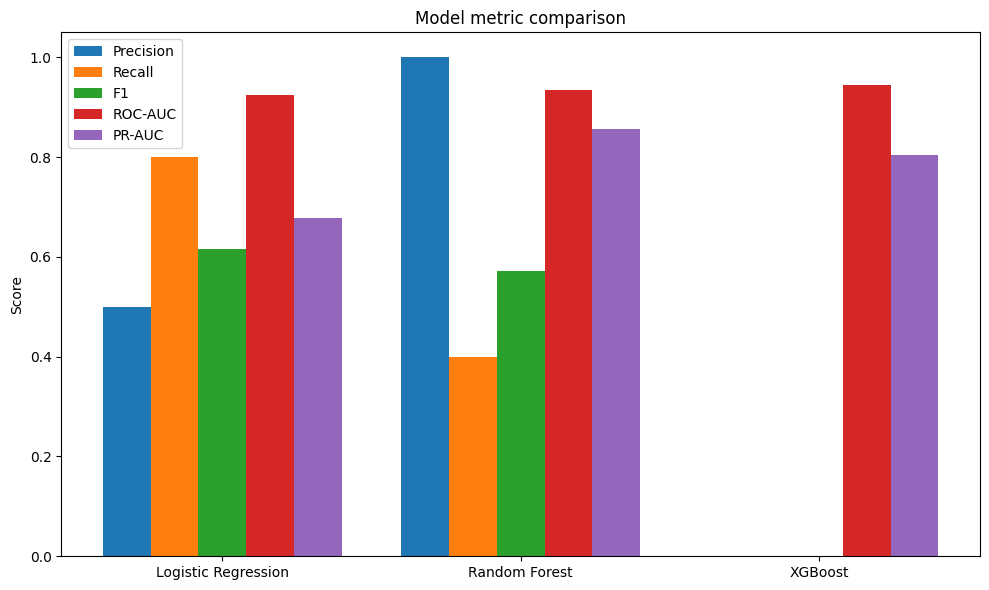

In [5]:
model_metrics = {name: payload['metrics'] for name, payload in results.items()}
plot_metric_bars(model_metrics, ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC'])
plt.savefig(Path.cwd().parent / 'reports' / 'figures' / 'metric_bars.png', dpi=150, bbox_inches='tight')
plt.show()

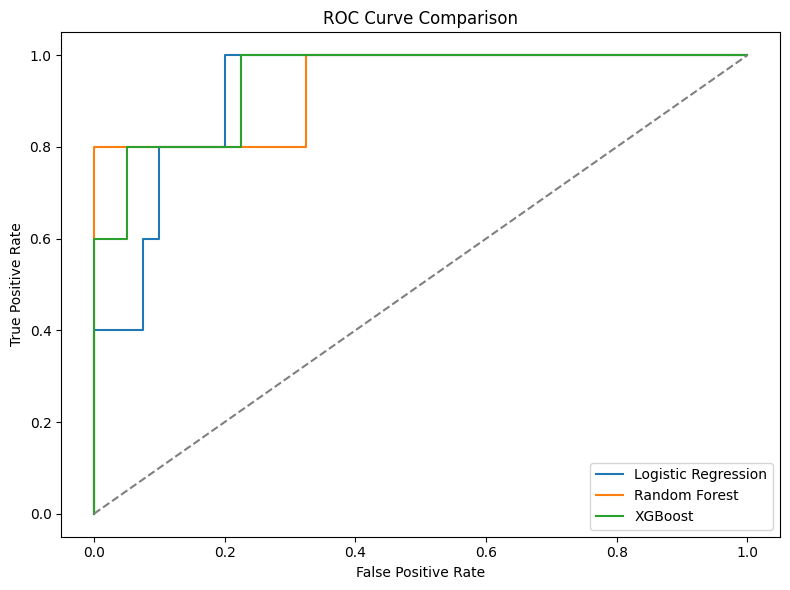

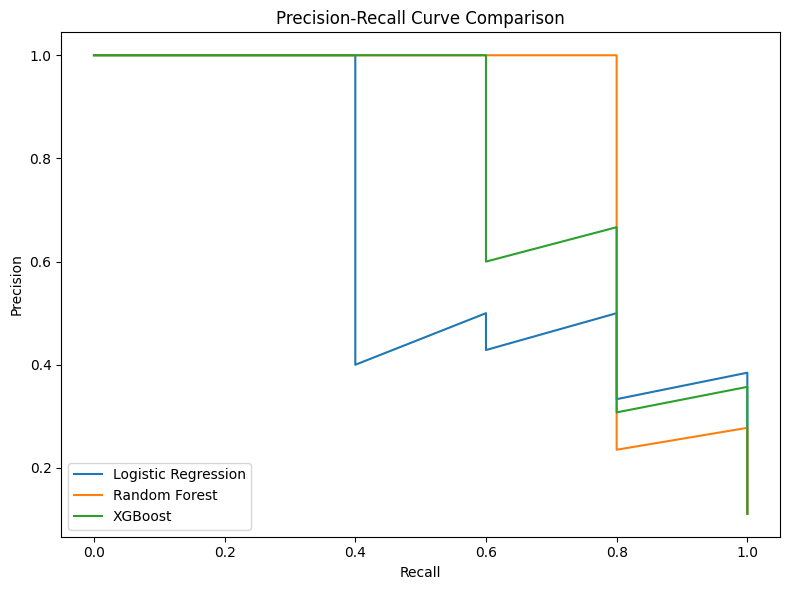

In [6]:
plot_roc_curve(results)
plt.savefig(Path.cwd().parent / 'reports' / 'figures' / 'roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
plot_precision_recall_curve(results)
plt.savefig(Path.cwd().parent / 'reports' / 'figures' / 'pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## Model selection guidance

Use multiple metrics, especially recall, precision, F1, ROC-AUC, and PR-AUC, to choose the most suitable classifier. For fraud detection, class imbalance makes PR-AUC especially valuable.

In [7]:
summary = pd.DataFrame({
    name: {k: round(v, 4) for k, v in payload['metrics'].items()
           if k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Balanced Accuracy']}
    for name, payload in results.items()
}).T
summary.to_csv(Path.cwd().parent / 'reports' / 'tables' / 'model_comparison.csv')
summary

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Balanced Accuracy
Logistic Regression,0.8889,0.5,0.8,0.6154,0.925,0.6769,0.85
Random Forest,0.9333,1.0,0.4,0.5714,0.935,0.8556,0.70
XGBoost,0.8889,0.0,0.0,0.0000,0.945,0.8048,0.50
